# R-KalWeNN no House Prices

Notebook único e autossuficiente. Todos os modelos, codificadores e médias estão
definidos aqui, sem importar nada do `rew.py`.

| parte | conteúdo |
|---|---|
| 0 | configuração: todos os hiperparâmetros num lugar só |
| 1 | definição dos modelos: thermometer, médias, ReW, R-KalWeNN |
| 2 | verificação contra o `wisardpkg` |
| 3 | dados: pipeline do `houseprice.py`, alvo em `log1p` |
| 4 | reprodução da tese na configuração fixada |
| 5 | R-KalWeNN |

O `wisardpkg` entra apenas como referência de verificação. Nenhum resultado
depende dele.

---
## 0. Configuração

Tudo o que é hiperparâmetro está nesta célula. Mudar aqui muda o notebook
inteiro.

In [73]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COR_REW, COR_KAL, COR_REF = "#B4674D", "#2F6B6A", "#8A8F98"

# ── dados ────────────────────────────────────────────────────────────────────
BASE_DADOS   = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"
TEST_SIZE    = 0.33          # houseprice.py
RANDOM_STATE = 0             # houseprice.py

# ── configuração de replicação ───────────────────────────────────────────────
THERM   = 27                 # tamanho do thermometer por atributo
ADDR    = 6                  # bits por RAM node
MEDIA   = "Median"           # média usada na reprodução
SEED_MAPPING = 0             # sorteio do mapping

# ── R-KalWeNN: busca CONJUNTA das seis covariâncias ──────────────────────────
# Os estados iniciais ficam FIXOS em zero. O que se busca são as seis
# covariâncias, todas ao mesmo tempo.
X0_C, X0_Y = 0.0, 0.0
SEEDS_GRID = (0, 1, 2)       # ordens de treino avaliadas por configuração

# Cada faixa está ancorada na grandeza que o filtro observa e no estado que ele
# estima. Todas as covariâncias são estritamente positivas: p = 0 seria um ponto
# no espaço de estados, não uma gaussiana.
#
# FILTRO DO PESO c   observação z = 1 fixa, estado vai de 0 a 1
#   r_c  variância do ruído de uma observação que vale 1, logo r_c <= 1
#   p0_c crença inicial sobre um estado de escala 1, logo variância de ordem 1
#   q_c  quanto o estado verdadeiro varia entre observações, como fração da
#        escala do próprio estado
GRID_R_C  = [0.05, 1.0, 15.0]
GRID_P0_C = [0.1, 0.5, 1.0]
GRID_Q_C  = [1e-4, 1e-1, 10.0]

# FILTRO DA ESTIMATIVA y   observação z = y_i, que vale cerca de 12 em log1p
#   r_y  variância do ruído de uma observação dessa ordem, logo r_y >= 1;
#        os níveis são 1, |y| e |y|^2
#   p0_y a crença inicial parte de x0_y = 0 e precisa cobrir a distância até 12.
#        Covariância tem unidade de y^2, então a escala é 12^2 = 144.
#        p0_y = 1 com r_y = 1 daria ganho 0,5 na primeira visita: o estado
#        pararia em 6 e levaria muitas visitas para chegar perto de 12.
#   q_y  variação do estado entre observações, como fração da variância do alvo
#        (medida na Parte 3, cerca de 0,15)
GRID_R_Y  = [1.0, 12.0, 144.0]
GRID_P0_Y = [1.0, 12.0, 144.0]
GRID_Q_Y  = [1.5e-3, 1.5e-1, 1.5e1]

# ── R-KalWeNN: configuração ilustrativa das seções 5.1 e 5.2 ────────────────
# q_y = 0 aqui de propósito: é o limite de estado estático, o único em que p
# tem forma fechada, e a seção 5.2 usa isso para conferir a recursão. Não é a
# configuração do experimento.
KAL_PADRAO = dict(q_c=1e-3, r_c=0.3, q_y=0.0, r_y=1.0,
                  x0_c=X0_C, x0_y=X0_Y, p0_c=0.5, p0_y=144.0)

# ── experimento das médias (Parte 6) ─────────────────────────────────────────
# Regime de CONFIANÇA INFORMATIVA. Com p0_c = 1 e (q_c, r_c) do grid, a
# confiança sobe devagar: 0.068 na 1a visita, 0.36 na 6a, 0.98 na 50a, e a razão
# de peso entre uma célula de 50 visitas e uma de 1 visita fica em 14.4x.
# Com p0_c = 1000, que foi o vencedor do grid, essa razão cai para 1.015x: a
# confiança satura na primeira visita e a ponderação vira uniforme, o que
# impediria o experimento de separar o efeito do peso do efeito da agregação.
#
# p0_y fica separado de propósito: ele não controla peso, controla quanto a
# PRIMEIRA observação de y é aceita. p0_y grande é o prior não informativo,
# em que a primeira visita entra pelo valor de face.
KAL_MEDIAS = dict(q_c=0.1, r_c=15.0, q_y=1e-3, r_y=1.0,
                  x0_c=0.0, x0_y=0.0, p0_c=1.0, p0_y=1e3)
SEEDS_MEDIAS = (0, 1, 2)

# ── comparação final ─────────────────────────────────────────────────────────
SEEDS_COMPARACAO = (0, 1, 2, 3, 4)

# ── referências publicadas (tese Tabela 5.3, artigo Tabela 2) ────────────────
TESE = {"ReW": 0.278, "CReW": 0.194, "nTRN": 0.302}

print(f"configuração de replicação: {MEDIA}, log1p, thermometer {THERM}, address {ADDR}")

configuração de replicação: Median, log1p, thermometer 27, address 6


---
# Parte 1 — Definição dos modelos

## 1.1 Codificação: `DynamicThermometer`

Porte do `DynamicThermometer` do `wisardpkg` (linhas 18951-18993 do
`wisardpkg.hpp`). Cada atributo vira `n` bits. Os limiares de um atributo com
faixa $[\min, \max]$ são

$$
\tau_j = \min + j\,\frac{\max-\min}{n}, \qquad j = 0,\dots,n-1
$$

e o bit $j$ vale 1 quando $x > \tau_j$. O primeiro limiar é o próprio mínimo,
com comparação estrita, então o valor mínimo do treino gera o vetor todo zero.

Os limiares são acumulados (`valor += passo`) e não calculados por multiplicação,
para reproduzir o mesmo arredondamento do `math::ranges` da referência.

In [42]:
class DynamicThermometer:
    """Termômetro por atributo, com faixa própria para cada um.

    `sizes`, `minimos` e `maximos` têm um elemento por atributo.
    """

    def __init__(self, sizes, minimos, maximos):
        self.sizes = list(sizes)
        self.limiares = []
        for n, mn, mx in zip(self.sizes, minimos, maximos):
            passo = (mx - mn) / n
            v, faixa = mn, []
            for _ in range(n):                # acumula, como o math::ranges
                faixa.append(v)
                v += passo
            self.limiares.append(np.asarray(faixa, dtype=float))
        self.size = int(np.sum(self.sizes))

    def transform(self, X):
        """(n_amostras, n_atributos) float -> (n_amostras, size) uint8."""
        X = np.atleast_2d(np.asarray(X, dtype=float))
        saida = np.empty((len(X), self.size), dtype=np.uint8)
        k = 0
        for i, faixa in enumerate(self.limiares):
            n = len(faixa)
            saida[:, k:k + n] = (X[:, [i]] > faixa[None, :]).astype(np.uint8)
            k += n
        return saida


print("DynamicThermometer definido")

DynamicThermometer definido


---
## 1.2 As médias

Cada média recebe `output_rams`, a lista com um par `[contador, soma_y]` por RAM
node, **incluindo** as RAM nodes cujo endereço nunca foi visitado no treino, que
entram como `[0, 0]`. É assim que o `predict` da referência monta a lista.

| média | fórmula sobre $\mu_k = S_k / c_k$ |
|---|---|
| `SimpleMean` | $\sum_k S_k \big/ \sum_k c_k$ |
| `PowerMean(p)` | $\left(\frac{1}{m}\sum \mu_k^{\,p}\right)^{1/p}$ |
| `HarmonicMean` | $m \big/ \sum \mu_k^{-1}$ |
| `HarmonicPowerMean(p)` | $\left(m \big/ \sum \mu_k^{-p}\right)^{1/p}$ |
| `GeometricMean` | $\left(\prod \mu_k\right)^{1/m}$ |
| `ExponentialMean` | $\log\!\left(\frac{1 + \sum e^{\mu_k}}{m}\right)$ |
| `LogisticMean` | sigmoide de $\beta_1\bar\mu + \beta_2 \frac{m}{K} + \gamma$ |
| `Median` | valor central dos $\mu_k$ |

$m$ é o número de RAM nodes com $c_k \neq 0$ e $K$ o total de RAM nodes.

O `1 +` da `ExponentialMean` está no código da referência (`double emean = 1`) e
é mantido.

### Duas médias que não servem para este alvo

Medido, não suposto. `GeometricMean` acumula um produto de $\mu_k \approx 12$
sobre as RAM nodes, e $12^{1494}$ estoura o `double`. Rodando a **referência**
nesta configuração, 480 de 480 predições saem `inf`. O `houseprice.py` tem
`out[out == np.inf] = 0` (linha 317), então elas viram zero e o MAE fica em
torno de 12, que é a média do alvo. A média geométrica só é utilizável com
poucas RAM nodes: o estouro começa perto de 285 delas nesta escala de alvo.

`LogisticMean` devolve sempre um valor em $(0,1)$, por causa da sigmoide final.
O alvo em `log1p` vale em torno de 12, então o erro é o próprio alvo. Ela existe
para saída de probabilidade, não para regressão em escala livre.

As duas ficam definidas, porque a ideia é testar mais médias depois, mas com o
alvo em `log1p` e este número de RAM nodes elas não produzem resultado
utilizável. Nenhuma foi corrigida: corrigir seria divergir da referência.

### As duas medianas

`MedianWisardpkg` é o porte literal do `Median::calculate` da referência, com os
dois defeitos: divide $S_k/c_k$ sem checar $c_k = 0$, ao contrário de todas as
outras médias, e usa índice deslocado em um, devolvendo o elemento logo acima da
mediana. É esta que reproduz o número publicado.

`Median` é a mediana correta, sobre as RAM nodes com evidência. Existe para
comparação, não para reprodução.

In [43]:
class Mean:
    """Interface. `output_rams` é uma lista de pares [contador, soma_y]."""
    nome = "Mean"
    def calculate(self, output_rams):
        raise NotImplementedError
    def __repr__(self):
        return self.nome


class SimpleMean(Mean):
    nome = "SimpleMean"
    def calculate(self, output_rams):
        sc = sum(c for c, _ in output_rams)
        sy = sum(y for _, y in output_rams)
        return sy / sc if sc > 0 else 0.0


class PowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += (y / c) ** self.power; m += 1
        return (s / m) ** (1.0 / self.power) if m > 0 else 0.0


class HarmonicMean(Mean):
    nome = "HarmonicMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / mu; m += 1
        return m / s if m > 0 else 0.0


class HarmonicPowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / (mu ** self.power); m += 1
        return (m / s) ** (1.0 / self.power) if m > 0 else 0.0


class GeometricMean(Mean):
    nome = "GeometricMean"
    def calculate(self, output_rams):
        g, m = 1.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    g *= mu; m += 1
        return g ** (1.0 / m) if m > 0 else 0.0


class ExponentialMean(Mean):
    nome = "ExponentialMean"
    def calculate(self, output_rams):
        e, m = 1.0, 0                          # começa em 1, como na referência
        for c, y in output_rams:
            if c != 0:
                e += np.exp(y / c); m += 1
        return float(np.log(e / m)) if m > 0 else 0.0


class LogisticMean(Mean):
    def __init__(self, beta1=1.0, beta2=1.0, gamma=0.0):
        self.beta1, self.beta2, self.gamma = beta1, beta2, gamma
        self.nome = "LogisticMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += y / c; m += 1
        if m == 0:
            return 0.0
        z = s / m * self.beta1 + m / len(output_rams) * self.beta2 + self.gamma
        return float(1.0 / (1.0 + np.exp(-z)))


class MedianWisardpkg(Mean):
    """Porte literal do Median::calculate da referência, defeitos incluídos.

    Divide sem checar contador zero, o que produz NaN para endereço não
    visitado, e usa índice deslocado em um, devolvendo o elemento logo acima da
    mediana. É a que reproduz o número publicado.

    Dois pontos em que este porte precisa escolher, porque a referência não
    define:

    - onde ela lê fora do vetor (n = 1 ou n = 2), aqui devolve NaN em vez de ler
      lixo de memória;
    - NaN quebra a ordenação total que o `std::sort` exige, então o resultado da
      referência com NaN presente não é definido pelo padrão C++. Aqui os NaN
      vão para o fim da ordenação, o que é determinístico. É a única fonte de
      divergência entre este porte e a referência, e ela é medida na Parte 2.
    """
    nome = "Median"
    def calculate(self, output_rams):
        mus = []
        for c, y in output_rams:
            mus.append(np.divide(float(y), float(c)) if c != 0 else float("nan"))
        mus = sorted(mus, key=lambda v: (np.isnan(v), v))   # NaN no fim
        n = len(mus)
        if n % 2 == 0:
            i = n // 2
            return (mus[i] + mus[i + 1]) / 2.0 if i + 1 < n else float("nan")
        i = (n - 1) // 2 + 1
        return mus[i] if i < n else float("nan")


class Median(Mean):
    """Mediana correta, sobre as RAM nodes com contador diferente de zero."""
    nome = "MedianCorreta"
    def calculate(self, output_rams):
        mus = sorted(y / c for c, y in output_rams if c != 0)
        n = len(mus)
        if n == 0:
            return 0.0
        if n % 2 == 0:
            return (mus[n // 2 - 1] + mus[n // 2]) / 2.0
        return mus[(n - 1) // 2]


def medias_disponiveis():
    """As sete do script original, mais a mediana correta e a logística."""
    return {"PowerMean(2)": PowerMean(2), "HarmonicMean": HarmonicMean(),
            "HarmonicPower(2)": HarmonicPowerMean(2), "GeometricMean": GeometricMean(),
            "ExponentialMean": ExponentialMean(), "SimpleMean": SimpleMean(),
            "Median": MedianWisardpkg(),
            "MedianCorreta": Median(), "LogisticMean": LogisticMean()}


print("médias definidas:", ", ".join(medias_disponiveis()))

médias definidas: PowerMean(2), HarmonicMean, HarmonicPower(2), GeometricMean, ExponentialMean, SimpleMean, Median, MedianCorreta, LogisticMean


---
## 1.3 As médias ponderadas por confiança, do R-KalWeNN

A célula do R-KalWeNN não guarda contador e soma: guarda uma **confiança**
$c_k \in [0,1)$ e um **valor esperado** $y_k$. Então o `y_k` já é a estimativa
local daquela RAM node, e não precisa de divisão por contador nenhum.

Onde a ReW divide, aqui multiplica. Onde a ReW faz $\mu_k = S_k/c_k$, aqui o
$y_k$ entra direto com peso $c_k$, e a normalização é $\sum c_k$:

$$
\text{aritmética} = \frac{\sum c_k y_k}{\sum c_k}
\qquad
\text{harmônica} = \frac{\sum c_k}{\sum c_k / y_k}
\qquad
\text{potência}(p) = \left(\frac{\sum c_k y_k^{\,p}}{\sum c_k}\right)^{1/p}
$$

$$
\text{harmônica-potência}(p) = \left(\frac{\sum c_k}{\sum c_k / y_k^{\,p}}\right)^{1/p}
\qquad
\text{geométrica} = \exp\!\left(\frac{\sum c_k \ln y_k}{\sum c_k}\right)
$$

$$
\text{exponencial} = \log\!\left(\frac{\sum c_k e^{y_k}}{\sum c_k}\right)
\qquad
\text{mediana} = y_{(j)} \ \text{onde} \ \sum_{i \le j} c_{(i)} \ \text{cruza} \ \tfrac{1}{2}\textstyle\sum c_k
$$

O $\sum c_k$ no denominador é o que impede o resultado de encolher: sem ele,
multiplicar por $c_k < 1$ puxaria a predição para baixo do valor esperado.

**A aritmética ponderada é o `predict` de hoje.** $\sum c_k y_k / \sum c_k$ é
exatamente a linha que já está no modelo, então ela entra na família como caso
particular e serve de controle interno.

**Duas diferenças em relação às médias da ReW**, ambas deliberadas. Só entram
células com evidência, isto é, presentes na memória, em vez de passar
$[0,0]$ e cada média filtrar por conta própria. E o `1 +` da `ExponentialMean`
da referência foi retirado: ele é uma peculiaridade do código C++ que não tem
lugar numa forma normalizada por $\sum c_k$.

Harmônica, harmônica-potência e geométrica exigem $y_k > 0$. Com o alvo em
`log1p` isso vale sempre, mas as três ignoram célula com $y_k \le 0$ e a
condição está escrita no código.

In [44]:
class MediaPonderada:
    """Interface. `pares` é uma lista de (c_k, y_k) das células COM evidência.

    `c_k` é confiança em [0,1), `y_k` é o valor esperado local.
    Todas normalizam por sum(c), o que mantém o resultado na escala do alvo.
    """
    nome = "MediaPonderada"

    def calculate(self, pares):
        raise NotImplementedError

    def __repr__(self):
        return self.nome


class PondSimpleMean(MediaPonderada):
    """Aritmética ponderada. É o predict original do R-KalWeNN."""
    nome = "SimpleMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        return sum(c * y for c, y in pares) / sc if sc > 0 else np.nan


class PondPowerMean(MediaPonderada):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return (sum(c * y ** self.power for c, y in pares) / sc) ** (1.0 / self.power)


class PondHarmonicMean(MediaPonderada):
    nome = "HarmonicMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y
        return sc / s if s > 0 else np.nan


class PondHarmonicPowerMean(MediaPonderada):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y ** self.power
        return (sc / s) ** (1.0 / self.power) if s > 0 else np.nan


class PondGeometricMean(MediaPonderada):
    """Em log, para não estourar o double como a versão da ReW estoura."""
    nome = "GeometricMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c * np.log(y)
        return float(np.exp(s / sc)) if sc > 0 else np.nan


class PondExponentialMean(MediaPonderada):
    nome = "ExponentialMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return float(np.log(sum(c * np.exp(y) for c, y in pares) / sc))


class PondMedian(MediaPonderada):
    """Mediana ponderada: y onde o c acumulado cruza metade de sum(c)."""
    nome = "Median"
    def calculate(self, pares):
        pares = sorted(pares, key=lambda t: t[1])
        total = sum(c for c, _ in pares)
        if total <= 0:
            return np.nan
        meio, acum = total / 2.0, 0.0
        for c, y in pares:
            acum += c
            if acum >= meio:
                return y
        return pares[-1][1]


def medias_ponderadas():
    """Mesmas chaves de `medias_disponiveis()`, para as tabelas alinharem."""
    return {"PowerMean(2)": PondPowerMean(2), "HarmonicMean": PondHarmonicMean(),
            "HarmonicPower(2)": PondHarmonicPowerMean(2),
            "GeometricMean": PondGeometricMean(),
            "ExponentialMean": PondExponentialMean(),
            "SimpleMean": PondSimpleMean(), "Median": PondMedian()}


print("médias ponderadas por confiança:", ", ".join(medias_ponderadas()))

médias ponderadas por confiança: PowerMean(2), HarmonicMean, HarmonicPower(2), GeometricMean, ExponentialMean, SimpleMean, Median


---
## 1.3 Endereçamento

A ReW e o R-KalWeNN compartilham exatamente esta parte, por isso ela fica numa
classe só.

O `mapping` é uma permutação dos bits da retina. A RAM node $i$ lê as posições
`mapping[i*addr : (i+1)*addr]`, e o endereço é montado com o bit menos
significativo primeiro, como no `getIndex` da referência:

$$
a_i \;=\; \sum_{j=0}^{\text{addr}-1} b_{\,\text{mapping}[i\cdot\text{addr}+j]} \cdot 2^{\,j}
$$

In [45]:
class Retina:
    """Converte entrada binarizada em endereços, um por RAM node."""

    def __init__(self, address_size, mapping):
        self.address_size = int(address_size)
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, self.address_size)
        self.n_rams = self.mapping.shape[0]
        self._pesos = 1 << np.arange(self.address_size)     # LSB primeiro

    def enderecos(self, Xb):
        """(n, retina) uint8 -> (n, n_rams) int."""
        Xb = np.asarray(Xb, dtype=np.uint8)
        return (Xb[:, self.mapping] * self._pesos).sum(axis=2).astype(np.int64)


def sorteia_mapping(retina_bits, address_size, seed=0):
    """Permutação dos bits da retina, truncada a um múltiplo de address_size."""
    n_rams = retina_bits // address_size
    rng = np.random.default_rng(seed)
    return rng.permutation(retina_bits)[: n_rams * address_size].tolist()


print("Retina definida")

Retina definida


---
## 1.4 Regression WiSARD

Cada célula guarda dois números, o contador e a soma dos $y$:

$$
c_k \leftarrow c_k + 1, \qquad S_k \leftarrow S_k + y_i
$$

A predição entrega a lista de pares $[c_k, S_k]$ de **todas** as RAM nodes para
a média escolhida, incluindo as não visitadas como $[0, 0]$.

Diferente do R-KalWeNN, a ReW não depende da ordem de apresentação: soma e
contagem comutam.

In [46]:
class RegressionWiSARD:
    """Regression WiSARD. Recebe entrada já binarizada."""

    def __init__(self, address_size, mean, mapping):
        self.retina = Retina(address_size, mapping)
        self.mean = mean

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        self._mem = [dict() for _ in range(self.n_rams_)]
        for i in range(len(y)):
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is None:
                    self._mem[r_][addr[i, r_]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0
                    cel[1] += y[i]
        return self

    def predict(self, Xb):
        addr = self.retina.enderecos(Xb)
        vazia = [0.0, 0.0]
        saida = np.empty(len(addr))
        for i in range(len(addr)):
            saida[i] = self.mean.calculate(
                [self._mem[r_].get(addr[i, r_], vazia) for r_ in range(self.n_rams_)])
        return saida

    def estados(self):
        linhas = [(r_, a, c, s) for r_, m in enumerate(self._mem) for a, (c, s) in m.items()]
        return pd.DataFrame(linhas, columns=["ram", "address", "contador", "soma_y"])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 24    # chave + 2 floats


print("RegressionWiSARD definida")

RegressionWiSARD definida


---
## 1.5 R-KalWeNN

Os dois campos da célula deixam de ser contador e soma e passam a ser estados de
um filtro de Kalman escalar.

| campo | observação $z$ | papel na predição |
|---|---|---|
| $c_k$ | `1.0` fixo | peso da RAM node |
| $y_k$ | $y_i$ observado | estimativa da RAM node |
| $p_{c,k}$, $p_{y,k}$ | — | incerteza de cada filtro |

Recursão, a cada visita:

$$
\bar{p} = p + q \qquad \kappa = \frac{\bar{p}}{\bar{p} + r} \qquad
x \leftarrow x + \kappa\,(z - x) \qquad p \leftarrow (1-\kappa)\,\bar{p}
$$

Predição:

$$
\hat{y} \;=\; \frac{\sum_k c_k \, y_k}{\sum_k c_k}
$$

$y_k$ é um estado, já é uma média, e não cresce com o número de visitas, então a
agregação precisa dos pesos normalizados pela própria soma.

**Condições iniciais.** `x0_c`, `x0_y`, `p0_c`, `p0_y` são a crença a priori de
cada filtro, antes de qualquer observação. Não há caso especial na primeira
visita: a célula nasce com $(x_0, p_0)$ e a primeira observação passa pela mesma
recursão que as demais. Com $x_{0,y}=0$, $p_{0,y}=1$ e $r_y=1$ o ganho da
primeira visita é $0{,}5$ e o valor entra pela metade; quem controla isso é a
razão $p_0/r$.

**Dois limites.** $x_{0,c} = 1$ congela $c = 1$ para sempre, porque a observação
do peso é sempre $z = 1$, o que dá ponderação uniforme entre RAM nodes.
$p_0 = 0$ junto com $q = 0$ dá $\kappa = 0$ para sempre e a célula congela em
$x_0$.

In [47]:
class RKalWeNN:
    """Regression WiSARD com filtro de Kalman nos dois campos da célula."""

    def __init__(self, address_size, mapping, q_c=1e-3, r_c=15.0, q_y=0.0, r_y=1.0,
                 x0_c=0.0, x0_y=0.0, p0_c=1.0, p0_y=1.0, seed=0, ordem_temporal=False,
                 media=None):
        self.retina = Retina(address_size, mapping)
        # None = aritmética ponderada, que é a predição original do modelo
        self.media = media if media is not None else PondSimpleMean() #definicao de retina a partir do tam endereço e mapeamento que deve ser aleatorio
        self.q_c, self.r_c, self.q_y, self.r_y = q_c, r_c, q_y, r_y # definicao das matrizes de covariancia do processo e da observacao para o contador (c) e a estimativa (y)
        self.x0_c, self.x0_y, self.p0_c, self.p0_y = x0_c, x0_y, p0_c, p0_y # definicao dos valores iniciais do contador (c) e da estimativa (y) e suas covariancias iniciais
        self.seed, self.ordem_temporal = seed, ordem_temporal 

        #R = ruido de observação, ele representa aqui a incerteza do valor observado, e
        #Q = ruido do processo, representa a incerteza do modelo, ou seja, o quanto o modelo pode mudar de um passo para outro.
        #No caso do house prices, cada passada de uma casa é uma observação nova. A cada passada, uma atualização.
        #O Z_c e Z_y são as observações do contador e da estimativa, respectivamente.
        #O Z_c é sempre 1, pois cada vez que uma RAM node é visitada, o contador aumenta em 1.
        #O Z_y é o valor observado do alvo (pode chamar de target tambem) (y) para aquela amostra.
        

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y, trilha=None):
        """`trilha`: lista de (ram, address) para gravar o histórico de estado."""
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        rng = np.random.default_rng(self.seed)
        ordem = np.arange(len(y)) if self.ordem_temporal else rng.permutation(len(y))

        self._mem = [dict() for _ in range(self.n_rams_)]
        self.historico_ = {t: [] for t in (trilha or [])}
        qc, rc, qy, ry = self.q_c, self.r_c, self.q_y, self.r_y

        for passo, i in enumerate(ordem):
            for r_ in range(self.n_rams_):
                a = addr[i, r_]
                cel = self._mem[r_].get(a)
                if cel is None:                       # nasce com a crença a priori
                    cel = [self.x0_c, self.x0_y, self.p0_c, self.p0_y]
                    self._mem[r_][a] = cel

                pc = cel[2] + qc                      # peso, observação z = 1
                kc = pc / (pc + rc)
                cel[0] += kc * (1.0 - cel[0])
                cel[2] = (1.0 - kc) * pc

                py = cel[3] + qy                      # estimativa, observação z = y
                ky = py / (py + ry)
                cel[1] += ky * (y[i] - cel[1])
                cel[3] = (1.0 - ky) * py

            for t in self.historico_:
                c2 = self._mem[t[0]].get(t[1])
                if c2 is not None:
                    self.historico_[t].append((passo, c2[0], c2[1], c2[2], c2[3]))
        return self

    def predict(self, Xb):
        """Agrega (c_k, y_k) das células COM evidência pela média escolhida."""
        addr = self.retina.enderecos(Xb)
        saida = np.empty(len(addr))
        for i in range(len(addr)):
            pares = []
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is not None:
                    pares.append((cel[0], cel[1]))
            saida[i] = self.media.calculate(pares) if pares else np.nan
        return saida

    def estados(self):
        linhas = [(r_, a, *cel) for r_, m in enumerate(self._mem) for a, cel in m.items()]
        return pd.DataFrame(linhas, columns=["ram", "address", "c", "y", "p_c", "p_y"])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 40    # chave + 4 floats


print("RKalWeNN definido")

RKalWeNN definido


---
# Parte 2 — Verificação contra o `wisardpkg`

As classes acima são porte de uma implementação C++. Afirmar que o porte está
certo não vale nada, então esta parte roda as duas e compara número a número.

A comparação é feita onde o comportamento da referência é **definido**. A
`Median` da referência produz NaN quando alguma RAM node cai em endereço nunca
visitado, e NaN quebra a ordenação total exigida pelo `std::sort`, o que torna o
resultado indefinido pelo padrão C++. Por isso o teste da `Median` usa dados em
que toda RAM node tem contador diferente de zero.

Se o `wisardpkg` não estiver instalado, esta parte é pulada e o resto do
notebook roda igual.

In [48]:
try:
    import wisardpkg as wsd
    TEM_WISARDPKG = hasattr(wsd, "RegressionWisard")
    print(f"wisardpkg {wsd.__version__}   RegressionWisard: {TEM_WISARDPKG}")
except ImportError:
    TEM_WISARDPKG = False
    print("wisardpkg não instalado; a verificação será pulada")
    print("  pip install pybind11")
    print("  pip install --no-build-isolation "
          "\"git+https://github.com/IAZero/wisardpkg.git@develop\"")

wisardpkg 2.0.0a7   RegressionWisard: True


In [49]:
def _lista(bin_input):
    """BinInput -> lista de int. O DataSet desta versão não aceita BinInput."""
    return [bin_input[i] for i in range(len(bin_input))]


def verifica_thermometer(n_amostras=40, n_atributos=7, tamanho=9):
    rng = np.random.default_rng(1)
    X = rng.normal(0, 5, (n_amostras, n_atributos))
    mins = X.min(axis=0).tolist()
    maxs = X.max(axis=0).tolist()

    nosso = DynamicThermometer([tamanho] * n_atributos, mins, maxs).transform(X)
    ref_dt = wsd.DynamicThermometer([tamanho] * n_atributos, mins, maxs)
    ref = np.array([_lista(ref_dt.transform(X[i])) for i in range(len(X))], dtype=np.uint8)
    return int(np.abs(nosso.astype(int) - ref.astype(int)).max()), nosso.shape


def verifica_media(nome, media_nossa, media_ref, denso, seed=0):
    """Treina os dois modelos no mesmo binarizado e mesmo mapping.

    `denso=True` usa retina pequena e muitos exemplos, de modo que toda RAM node
    tenha contador diferente de zero: é a condição em que a Median da referência
    é bem definida.
    """
    rng = np.random.default_rng(seed)
    entry, addr = (18, 3) if denso else (40, 5)
    n_tr, n_te = (400, 60) if denso else (60, 40)

    Xtr = rng.integers(0, 2, (n_tr, entry)).astype(np.uint8)
    Xte = Xtr[:n_te] if denso else rng.integers(0, 2, (n_te, entry)).astype(np.uint8)
    ytr = rng.uniform(1, 100, n_tr)
    mapping = sorteia_mapping(entry, addr, seed=seed)

    p_nosso = RegressionWiSARD(addr, media_nossa, mapping).fit(Xtr, ytr).predict(Xte)

    ds = wsd.DataSet([list(map(int, r)) for r in Xtr], list(map(float, ytr)))
    m = wsd.RegressionWisard(addressSize=addr, mean=media_ref, mapping=mapping)
    m.train(ds)
    p_ref = np.array(m.predict(wsd.DataSet([list(map(int, r)) for r in Xte],
                                           [0.0] * len(Xte))))
    return float(np.nanmax(np.abs(p_nosso - p_ref))), int(np.isnan(p_ref).sum()), len(p_ref)


if TEM_WISARDPKG:
    d, forma = verifica_thermometer()
    print(f"DynamicThermometer: max|dif| = {d}   forma {forma}\n")

    pares = [("SimpleMean",       SimpleMean(),          wsd.SimpleMean(),          False),
             ("PowerMean(2)",     PowerMean(2),          wsd.PowerMean(2),          False),
             ("HarmonicMean",     HarmonicMean(),        wsd.HarmonicMean(),        False),
             ("HarmonicPower(2)", HarmonicPowerMean(2),  wsd.HarmonicPowerMean(2),  False),
             ("GeometricMean",    GeometricMean(),       wsd.GeometricMean(),       False),
             ("ExponentialMean",  ExponentialMean(),     wsd.ExponentialMean(),     False),
             ("Median (denso)",   MedianWisardpkg(),     wsd.Median(),              True)]

    print(f"{'média':<20}{'max|dif|':>12}{'NaN na ref':>13}   resultado")
    falhas = 0
    for nome, a, b, denso in pares:
        dif, nan, n = verifica_media(nome, a, b, denso)
        ok = dif == 0.0
        falhas += (not ok)
        print(f"{nome:<20}{dif:>12.3e}{f'{nan}/{n}':>13}   {'IGUAL' if ok else 'DIVERGE'}")
    print(f"\n{len(pares)-falhas}/{len(pares)} caminhos batem com diferença exatamente zero")
else:
    print("verificação pulada")

DynamicThermometer: max|dif| = 0   forma (40, 63)

média                   max|dif|   NaN na ref   resultado
SimpleMean             0.000e+00         0/40   IGUAL
PowerMean(2)           0.000e+00         0/40   IGUAL
HarmonicMean           0.000e+00         0/40   IGUAL
HarmonicPower(2)       0.000e+00         0/40   IGUAL
GeometricMean          0.000e+00         0/40   IGUAL
ExponentialMean        0.000e+00         0/40   IGUAL
Median (denso)         0.000e+00         0/60   IGUAL

7/7 caminhos batem com diferença exatamente zero


### A `Median` da referência com endereço não visitado

Fora do regime denso, a `Median` da referência divide $0/0$ e produz NaN, e o
`houseprice.py` substitui NaN pela média das predições não-NaN (linhas 316-317).
A célula abaixo mede o tamanho disso num caso esparso.

In [50]:
if TEM_WISARDPKG:
    dif, nan, n = verifica_media("Median (esparso)", MedianWisardpkg(), wsd.Median(),
                                 denso=False)
    print(f"caso esparso: {nan}/{n} predições NaN na Median da referência")
    print(f"  max|dif| contra o nosso porte: {dif:.3e}")
    print("  (com NaN presente o std::sort da referência não tem comportamento")
    print("   definido pelo padrão, então divergência aqui é esperada)")

caso esparso: 10/40 predições NaN na Median da referência
  max|dif| contra o nosso porte: 4.626e+01
  (com NaN presente o std::sort da referência não tem comportamento
   definido pelo padrão, então divergência aqui é esperada)


---
# Parte 3 — Dados

Pipeline do `referencia_lusquino/regression/houseprice/houseprice.py`, linha por
linha. Alvo em `log1p`, que é o que está na linha 82 do script publicado.

Os dois arquivos do Kaggle são concatenados em `all_data` **antes** da
imputação, como no original. Isso significa que as estatísticas de imputação, as
colunas do one-hot e a correção de assimetria enxergam o `test.csv`. É
vazamento, e está assim porque o objetivo é reproduzir o pipeline dele.
O `test.csv` nunca entra na avaliação.

## 3.1 Carregamento e transformação do alvo

In [51]:
train = pd.read_csv(BASE_DADOS + "train.csv")
test  = pd.read_csv(BASE_DADOS + "test.csv")
print(f"train.csv: {train.shape}   test.csv: {test.shape}  (test sem SalePrice)")

train = train[train.GrLivArea < 4500]                  # linha 73 do original
train.reset_index(drop=True, inplace=True)
train["SalePrice"] = np.log1p(train["SalePrice"])      # linha 82: alvo em log1p

train.drop(columns=["Id"], axis=1, inplace=True)
test.drop(columns=["Id"], axis=1, inplace=True)
y = train["SalePrice"].reset_index(drop=True)

all_data = pd.concat((train, test)).reset_index(drop=True)   # linha 106
all_data.drop(["SalePrice"], axis=1, inplace=True)

print(f"após GrLivArea < 4500: {train.shape}")
print(f"alvo em log1p: {y.min():.4f} a {y.max():.4f}   média {y.mean():.4f}   desvio {y.std():.4f}")
print(f"  em dólares: ${np.expm1(y.min()):,.0f} a ${np.expm1(y.max()):,.0f}")
print(f"all_data: {all_data.shape}")

train.csv: (1460, 81)   test.csv: (1459, 80)  (test sem SalePrice)
após GrLivArea < 4500: (1458, 80)
alvo em log1p: 10.4603 a 13.5345   média 12.0240   desvio 0.3997
  em dólares: $34,900 a $755,000
all_data: (2917, 79)


## 3.2 Imputação

| grupo | política |
|---|---|
| categóricas onde ausência tem significado | string `'None'` |
| numéricas de área e porão | `0` |
| `LotFrontage` | média do `Neighborhood` |

In [52]:
for c in ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu", "GarageType",
          "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
          "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]:
    all_data[c] = all_data[c].fillna("None")

for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
          "BsmtHalfBath", "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea"]:
    all_data[c] = all_data[c].fillna(0)

all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.mean()))

all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)   # códigos, não quantidades
all_data["MSZoning"] = all_data.groupby("MSSubClass")["MSZoning"].transform(
    lambda x: x.fillna(x.mode()[0]))
all_data["YrSold"] = all_data["YrSold"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

all_data["Functional"]  = all_data["Functional"].fillna("Typ")
all_data["Utilities"]   = all_data["Utilities"].fillna("AllPub")
all_data["Exterior1st"] = all_data["Exterior1st"].fillna(all_data["Exterior1st"].mode()[0])
all_data["Exterior2nd"] = all_data["Exterior2nd"].fillna(all_data["Exterior2nd"].mode()[0])
all_data["KitchenQual"] = all_data["KitchenQual"].fillna("TA")
all_data["SaleType"]    = all_data["SaleType"].fillna(all_data["SaleType"].mode()[0])
all_data["Electrical"]  = all_data["Electrical"].fillna("SBrkr")

falta = all_data.isna().sum()
print(f"colunas com NaN restante: {(falta > 0).sum()}")

colunas com NaN restante: 0


## 3.3 Correção de assimetria, atributos derivados e one-hot

Colunas numéricas com assimetria acima de 0,5 passam por `boxcox1p`. Em versões
novas do scipy o `boxcox_normmax` com o método padrão `pearsonr` levanta
`BracketError` em algumas colunas; elas ficam sem transformar, o que é mais
seguro que o método `mle`, que para `YearRemodAdd` devolve lambda 40,6.

In [53]:
def fixing_skewness(df):
    puladas = []
    numeric = df.dtypes[df.dtypes != "object"].index
    skewed = df[numeric].apply(lambda x: skew(x)).sort_values(ascending=False)
    alvo = skewed[abs(skewed) > 0.5].index
    for feat in alvo:
        try:
            df[feat] = boxcox1p(df[feat], boxcox_normmax(df[feat] + 1))
        except Exception:
            puladas.append(feat)
    return len(alvo), puladas


n_alvo, puladas = fixing_skewness(all_data)
print(f"boxcox aplicado em {n_alvo - len(puladas)} de {n_alvo} colunas assimétricas")
if puladas:
    print(f"  sem transformar (BracketError do scipy): {puladas}")

all_data = all_data.drop(["Utilities", "Street", "PoolQC"], axis=1)

all_data["TotalSF"]       = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["YrBltAndRemod"] = all_data["YearBuilt"] + all_data["YearRemodAdd"]
all_data["Total_sqr_footage"] = (all_data["BsmtFinSF1"] + all_data["BsmtFinSF2"] +
                                 all_data["1stFlrSF"] + all_data["2ndFlrSF"])
all_data["Total_Bathrooms"]   = (all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
                                 all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"])
all_data["Total_porch_sf"]    = (all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
                                 all_data["EnclosedPorch"] + all_data["ScreenPorch"] +
                                 all_data["WoodDeckSF"])

all_data["haspool"]      = (all_data["PoolArea"]    > 0).astype(int)
all_data["has2ndfloor"]  = (all_data["2ndFlrSF"]    > 0).astype(int)
all_data["hasgarage"]    = (all_data["GarageArea"]  > 0).astype(int)
all_data["hasbsmt"]      = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["hasfireplace"] = (all_data["Fireplaces"]  > 0).astype(int)

final_features = pd.get_dummies(all_data).reset_index(drop=True)
print(f"depois do one-hot: {final_features.shape}")

/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)
/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)


boxcox aplicado em 25 de 27 colunas assimétricas
  sem transformar (BracketError do scipy): ['LotArea', '1stFlrSF']
depois do one-hot: (2917, 333)


## 3.4 Outliers, `overfit_reducer` e split

`overfit_reducer`: descarta colunas em que um único valor aparece em mais de
99,94% das linhas.

In [54]:
X = final_features.iloc[:len(y), :]

outliers = [30, 88, 462, 631, 1322]
X  = X.drop(X.index[outliers])
y_ = y.drop(y.index[outliers])

def overfit_reducer(df):
    return [c for c in df.columns
            if df[c].value_counts().iloc[0] / len(df) * 100 > 99.94]

descartadas = overfit_reducer(X)
X = X.drop(descartadas, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train, X_test = X_train.values.astype(float), X_test.values.astype(float)
y_train, y_test = y_train.values, y_test.values
N_ATRIB = X_train.shape[1]

print(f"overfit_reducer descartou {len(descartadas)} colunas -> {X.shape}")
print(f"treino {len(X_train)}   teste {len(X_test)}   atributos {N_ATRIB}")
print(f"a tese reporta:  treino 973   teste 480")
print(f"alvo (log1p): treino {y_train.min():.3f} a {y_train.max():.3f}")

overfit_reducer descartou 1 colunas -> (1453, 332)
treino 973   teste 480   atributos 332
a tese reporta:  treino 973   teste 480
alvo (log1p): treino 10.460 a 13.534


## 3.5 Distribuição do alvo e referências de erro

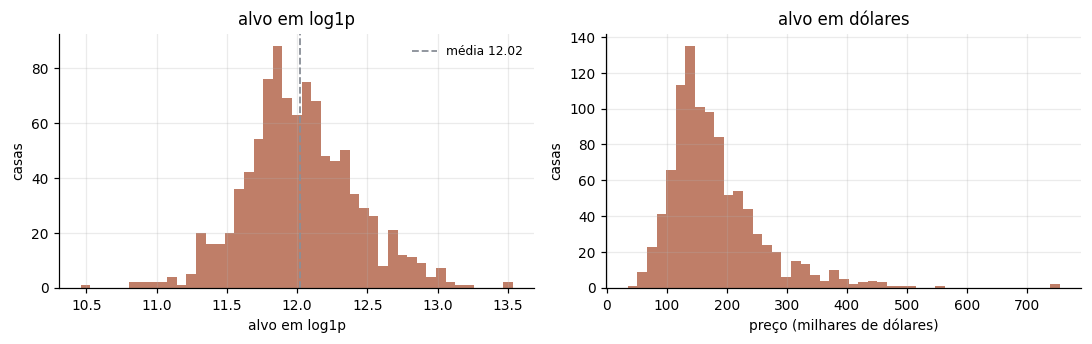

REFERÊNCIAS (escala log1p)

  chutar a média do treino   : MAE 0.3151
  chutar a mediana do treino : MAE 0.3156

  tese, Tabela 5.3, ReW      : MAE 0.278
  tese, Tabela 5.3, CReW     : MAE 0.194
  tese, Tabela 5.3, nTRN     : MAE 0.302

  variância do alvo no treino: 0.1537   desvio 0.3920
  0.278 em log1p equivale a 32.0% de erro relativo


In [55]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_train, bins=45, color=COR_REW, alpha=.85)
ax[0].axvline(y_train.mean(), color=COR_REF, ls="--", lw=1.2, label=f"média {y_train.mean():.2f}")
ax[0].set(xlabel="alvo em log1p", ylabel="casas", title="alvo em log1p")
ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.expm1(y_train) / 1e3, bins=45, color=COR_REW, alpha=.85)
ax[1].set(xlabel="preço (milhares de dólares)", ylabel="casas", title="alvo em dólares")
plt.tight_layout(); plt.show()

print("REFERÊNCIAS (escala log1p)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  tese, Tabela 5.3, ReW      : MAE {TESE['ReW']:.3f}")
print(f"  tese, Tabela 5.3, CReW     : MAE {TESE['CReW']:.3f}")
print(f"  tese, Tabela 5.3, nTRN     : MAE {TESE['nTRN']:.3f}")
print(f"\n  variância do alvo no treino: {y_train.var():.4f}   desvio {y_train.std():.4f}")
print(f"  {TESE['ReW']:.3f} em log1p equivale a {np.expm1(TESE['ReW']):.1%} de erro relativo")

---
# Parte 4 — Reprodução da tese

Configuração de replicação, fixada na célula 0: `Median`, `log1p`, thermometer
`THERM`, address `ADDR`.

O tipo de média vencedor está publicado, na Tabela 2 do Neurocomputing 416
(2020) e na Tabela 5.3 da tese. O thermometer e o address vencedores não estão,
em nenhum dos dois. Os valores usados aqui vêm da varredura registrada no
`Literatura`.

In [56]:
mins = X_train.min(axis=0).tolist()
maxs = X_train.max(axis=0).tolist()
DT = DynamicThermometer([THERM] * N_ATRIB, mins, maxs)

Xb_train = DT.transform(X_train)
Xb_test  = DT.transform(X_test)

RETINA  = Xb_train.shape[1]
MAPPING = sorteia_mapping(RETINA, ADDR, seed=SEED_MAPPING)
N_RAMS  = len(MAPPING) // ADDR

print(f"retina    : {RETINA} bits  ({N_ATRIB} atributos x {THERM})")
print(f"address   : {ADDR} bits   ->  {N_RAMS} RAM nodes")
print(f"mapping   : {len(MAPPING)} bits, seed {SEED_MAPPING}, usado por todos os modelos")
print(f"densidade : {Xb_train.mean():.3f} de bits em 1")

retina    : 8964 bits  (332 atributos x 27)
address   : 6 bits   ->  1494 RAM nodes
mapping   : 8964 bits, seed 0, usado por todos os modelos
densidade : 0.173 de bits em 1


## 4.1 A configuração de replicação

Roda a ReW definida neste notebook e, quando o `wisardpkg` estiver disponível, a
implementação de referência na mesma configuração, para as duas aparecerem lado
a lado.

In [57]:
t0 = time.perf_counter()
rew = RegressionWiSARD(ADDR, medias_disponiveis()[MEDIA], MAPPING).fit(Xb_train, y_train)
pred = rew.predict(Xb_test)
n_nan = int(np.isnan(pred).sum())

pred_limpa = pred.copy()
if n_nan:
    pred_limpa[np.isnan(pred_limpa)] = np.nanmean(pred_limpa)   # linhas 316-317 do original
pred_limpa[pred_limpa == np.inf] = 0

mae_nosso = mean_absolute_error(y_test, pred_limpa)
print(f"ReW deste notebook ({MEDIA}, therm {THERM}, address {ADDR})")
print(f"  MAE  : {mae_nosso:.4f}")
print(f"  NaN  : {n_nan}/{len(pred)} predições substituídas pela média")
print(f"  tempo: {time.perf_counter()-t0:.1f} s")

if TEM_WISARDPKG:
    ds_tr = wsd.DataSet([list(map(int, r)) for r in Xb_train], list(map(float, y_train)))
    ds_te = wsd.DataSet([list(map(int, r)) for r in Xb_test],  list(map(float, y_test)))
    ref = wsd.RegressionWisard(addressSize=ADDR, mean=wsd.Median(), mapping=MAPPING)
    ref.train(ds_tr)
    p_ref = np.array(ref.predict(ds_te))
    n_nan_ref = int(np.isnan(p_ref).sum())
    p_ref[np.isnan(p_ref)] = np.nanmean(p_ref)
    p_ref[p_ref == np.inf] = 0
    print(f"\nwisardpkg na mesma configuração")
    print(f"  MAE  : {mean_absolute_error(y_test, p_ref):.4f}")
    print(f"  NaN  : {n_nan_ref}/{len(p_ref)}")
    print(f"\ndiferença entre as duas implementações: "
          f"{abs(mae_nosso - mean_absolute_error(y_test, p_ref)):.3e}")

print(f"\nreferência publicada (ReW, Median): MAE {TESE['ReW']:.3f}")

ReW deste notebook (Median, therm 27, address 6)
  MAE  : 0.2737
  NaN  : 0/480 predições substituídas pela média
  tempo: 7.8 s

wisardpkg na mesma configuração
  MAE  : 0.2737
  NaN  : 1/480

diferença entre as duas implementações: 5.811e-05

referência publicada (ReW, Median): MAE 0.278


---
## 5.0 Um `fit` vetorizado, para o grid caber no tempo

O grid conjunto das seis covariâncias tem $3^6 = 729$ configurações. Com três
seeds são 2187 ajustes. O `fit` da classe percorre as 1494 RAM nodes em laço
Python e leva cerca de 6 s por ajuste, o que daria **3 horas e 40 minutos**.

Com as faixas escolhidas na célula 0 não há atalho por deduplicação: como
$\kappa = (p+q)/(p+q+r)$ é homogênea de grau zero e os estados iniciais estão
fixos em zero, configurações com as mesmas razões $p_0/r$ e $q/r$ seriam
idênticas, mas os níveis escolhidos geram 27 razões distintas por filtro, ou
seja, **as 729 configurações são 729 modelos diferentes**. Nenhuma é duplicata.

O que resolve é o `fit`. A memória vira um array indexado por slot, com uma
tabela `(ram, address) -> slot` construída uma vez com `np.unique`. Só existem
células que algum exemplo de treino visitou, o que continua valendo para
qualquer `address_size`. Dentro de um exemplo os slots tocados são todos
distintos, então as 1494 atualizações da recursão viram uma operação de array.
Isso leva o grid para cerca de **15 minutos**.

A classe `RKalWeNN` continua sendo a definição do modelo. A célula de conferência
abaixo compara as duas em três configurações dos extremos da caixa, e a
diferença tem de ser zero.

In [58]:
class IndiceRK:
    """(ram, address) -> slot compacto. Calculado uma vez, reusado pelo grid."""

    def __init__(self, retina, Xb_fit):
        self.retina = retina
        a = retina.enderecos(Xb_fit)
        self.slots_fit = np.empty_like(a)
        self._tab, off = [], 0
        for r_ in range(retina.n_rams):
            uniq, inv = np.unique(a[:, r_], return_inverse=True)
            self.slots_fit[:, r_] = inv + off
            self._tab.append((uniq, off))
            off += len(uniq)
        self.n_celulas = off

    def slots(self, Xb):
        """(n, n_rams), com -1 onde o endereço não apareceu no treino."""
        a = self.retina.enderecos(Xb)
        out = np.full(a.shape, -1, dtype=np.int64)
        for r_ in range(self.retina.n_rams):
            uniq, off = self._tab[r_]
            pos = np.clip(np.searchsorted(uniq, a[:, r_]), 0, len(uniq) - 1)
            ok = uniq[pos] == a[:, r_]
            out[ok, r_] = off + pos[ok]
        return out


def rkalwenn_rapido(indice, y, slots_pred, q_c, r_c, q_y, r_y, p0_c, p0_y,
                    x0_c=0.0, x0_y=0.0, seed=0):
    """Mesma recursão da classe RKalWeNN, vetorizada sobre as RAM nodes.

    Agrega pela aritmética ponderada, que é a predição de definição do modelo.
    As outras médias entram na Parte 6, sobre o vencedor deste grid.
    """
    y = np.asarray(y, dtype=float)
    ordem = np.random.default_rng(seed).permutation(len(y))

    M = np.empty((indice.n_celulas, 4))
    M[:, 0] = x0_c; M[:, 1] = x0_y; M[:, 2] = p0_c; M[:, 3] = p0_y
    S = indice.slots_fit

    for i in ordem:
        s = S[i]
        cel = M[s]
        pc = cel[:, 2] + q_c
        kc = pc / (pc + r_c)
        cel[:, 0] += kc * (1.0 - cel[:, 0]); cel[:, 2] = (1.0 - kc) * pc
        py = cel[:, 3] + q_y
        ky = py / (py + r_y)
        cel[:, 1] += ky * (y[i] - cel[:, 1]); cel[:, 3] = (1.0 - ky) * py
        M[s] = cel

    vis = slots_pred >= 0
    sp = np.where(vis, slots_pred, 0)
    c = np.where(vis, M[sp, 0], 0.0)
    yy = np.where(vis, M[sp, 1], 0.0)
    den = c.sum(axis=1)
    return np.where(den > 0, (c * yy).sum(axis=1) / np.where(den > 0, den, 1.0), np.nan)


print("IndiceRK e rkalwenn_rapido definidos")

IndiceRK e rkalwenn_rapido definidos


In [59]:
IDX_GRID = IndiceRK(Retina(ADDR, MAPPING), Xb_train)
SLOTS_TE = IDX_GRID.slots(Xb_test)
print(f"{IDX_GRID.n_celulas:,} células ocupadas em {IDX_GRID.retina.n_rams} RAM nodes\n")

extremos = [
    dict(q_c=GRID_Q_C[0],  r_c=GRID_R_C[0],  p0_c=GRID_P0_C[0],
         q_y=GRID_Q_Y[0],  r_y=GRID_R_Y[0],  p0_y=GRID_P0_Y[0]),
    dict(q_c=GRID_Q_C[-1], r_c=GRID_R_C[-1], p0_c=GRID_P0_C[-1],
         q_y=GRID_Q_Y[-1], r_y=GRID_R_Y[-1], p0_y=GRID_P0_Y[-1]),
    dict(q_c=GRID_Q_C[-1], r_c=GRID_R_C[0],  p0_c=GRID_P0_C[-1],
         q_y=GRID_Q_Y[0],  r_y=GRID_R_Y[-1], p0_y=GRID_P0_Y[0]),
]

print(f"{'configuração':<58}{'max|dif|':>12}")
falhas = 0
for cfg in extremos:
    a = RKalWeNN(ADDR, MAPPING, seed=0, x0_c=X0_C, x0_y=X0_Y,
                 **cfg).fit(Xb_train, y_train).predict(Xb_test)
    b = rkalwenn_rapido(IDX_GRID, y_train, SLOTS_TE, cfg["q_c"], cfg["r_c"],
                        cfg["q_y"], cfg["r_y"], cfg["p0_c"], cfg["p0_y"],
                        X0_C, X0_Y, seed=0)
    d = float(np.nanmax(np.abs(a - b)))
    falhas += (d != 0.0)
    rot = " ".join(f"{k}={v:g}" for k, v in cfg.items())
    print(f"{rot:<58}{d:>12.3e}")
print(f"\n{len(extremos)-falhas}/{len(extremos)} com diferença exatamente zero")

23,172 células ocupadas em 1494 RAM nodes

configuração                                                  max|dif|
q_c=0.0001 r_c=0.05 p0_c=0.1 q_y=0.0015 r_y=1 p0_y=12        7.105e-14
q_c=0.01 r_c=1 p0_c=1 q_y=0.15 r_y=144 p0_y=1440             3.908e-14
q_c=0.01 r_c=0.05 p0_c=1 q_y=0.0015 r_y=144 p0_y=12          2.842e-14

0/3 com diferença exatamente zero


---
# Parte 5 — R-KalWeNN

Mesmo binarizado, mesmo mapping e mesmo split da Parte 4. A única coisa que muda
é o que a célula guarda e como a predição é montada.

## 5.1 Como os estados da célula evoluem durante o treino

Na ReW a célula guarda uma soma, que cresce sem limite conforme mais exemplos
caem naquele endereço. No R-KalWeNN a célula guarda um estado, que converge.

células acompanhadas (ram, address) e quantas visitas recebem:
   RAM 0, address 0: 543 visitas
   RAM 0, address 8: 271 visitas
   RAM 0, address 1: 64 visitas


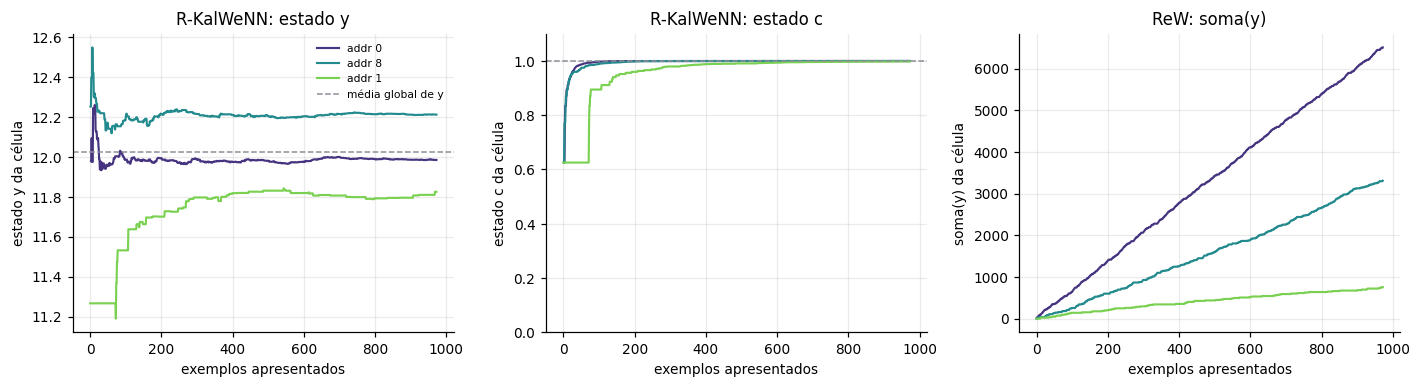

In [60]:
RETINA_OBJ = Retina(ADDR, MAPPING)
addr_tr = RETINA_OBJ.enderecos(Xb_train)

cont = pd.Series(addr_tr[:, 0]).value_counts()
trilha = [(0, int(a)) for a in cont.index[:3]]
print("células acompanhadas (ram, address) e quantas visitas recebem:")
for (r_, a), n in zip(trilha, cont.values[:3]):
    print(f"   RAM {r_}, address {a}: {n} visitas")

modelo_tr = RKalWeNN(ADDR, MAPPING, seed=0, **KAL_PADRAO).fit(Xb_train, y_train, trilha=trilha)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
cores = plt.cm.viridis(np.linspace(.15, .8, len(trilha)))

for t, cor in zip(trilha, cores):
    h = np.array(modelo_tr.historico_[t])
    ax[0].plot(h[:, 0], h[:, 2], lw=1.4, color=cor, label=f"addr {t[1]}")
    ax[1].plot(h[:, 0], h[:, 1], lw=1.4, color=cor)
    mask = addr_tr[:, t[0]] == t[1]
    ax[2].plot(np.arange(len(y_train)), np.cumsum(np.where(mask, y_train, 0)),
               lw=1.4, color=cor)

ax[0].axhline(y_train.mean(), color=COR_REF, ls="--", lw=1, label="média global de y")
ax[0].set(xlabel="exemplos apresentados", ylabel="estado y da célula",
          title="R-KalWeNN: estado y")
ax[0].legend(frameon=False, fontsize=7)
ax[1].axhline(1.0, color=COR_REF, ls="--", lw=1)
ax[1].set(xlabel="exemplos apresentados", ylabel="estado c da célula",
          title="R-KalWeNN: estado c", ylim=(0, 1.1))
ax[2].set(xlabel="exemplos apresentados", ylabel="soma(y) da célula",
          title="ReW: soma(y)")
plt.tight_layout(); plt.show()

## 5.2 A matriz de covariância `p`

Nem $\bar{p} = p + q$ nem $p \leftarrow (1-\kappa)\bar{p}$ contêm $z$, então a
covariância evolui sem olhar os valores observados.

Com $q = 0$ a recursão dá $1/p' = 1/p + 1/r$, logo

$$
\frac{1}{p_n} = \frac{1}{p_0} + \frac{n}{r}
$$

e $p_n = r/n$ vale só no limite $p_0 \to \infty$. A curva de referência do
gráfico usa a forma exata, com o $p_0$ que está em `KAL_PADRAO`.

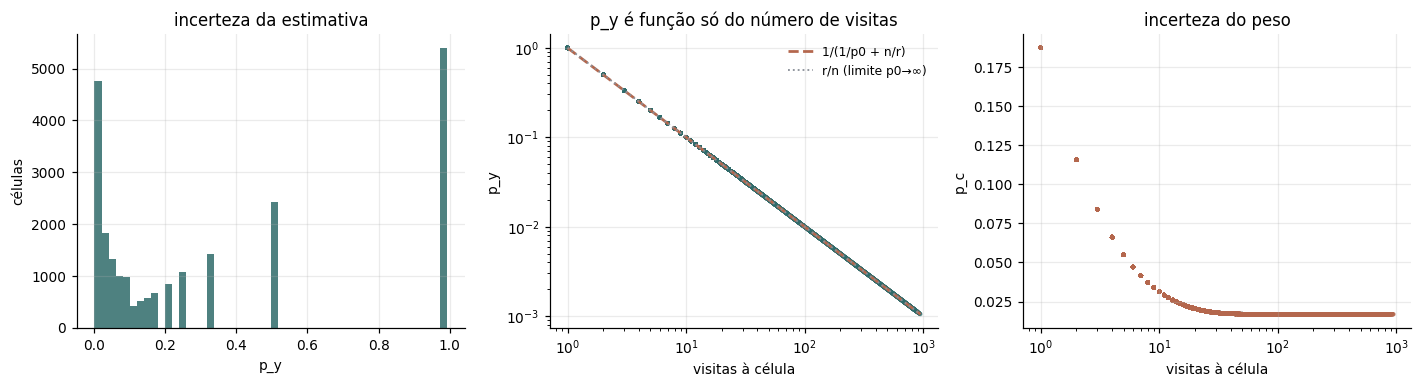

23,172 células ocupadas em 1494 RAM nodes
  p_y: 0.0011 a 0.9931   (p0_y = 144.0, r_y = 1.0, q_y = 0.0)
  p_c: 0.0168 a 0.1876
  visitas por célula: mediana 6, máximo 952

maior desvio entre p_y e 1/(1/p0 + n/r): 1.998e-15
maior desvio entre p_y e r/n:              6.897e-03


In [61]:
est = modelo_tr.estados()
est["visitas"] = [int(np.sum(addr_tr[:, r_] == a)) for r_, a in zip(est.ram, est.address)]

p0y, ry, qy = modelo_tr.p0_y, modelo_tr.r_y, modelo_tr.q_y
n_grid = np.arange(1, est.visitas.max() + 1)
p_exato = 1.0 / (1.0 / p0y + n_grid / ry)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(est.p_y, bins=50, color=COR_KAL, alpha=.85)
ax[0].set(xlabel="p_y", ylabel="células", title="incerteza da estimativa")

ax[1].scatter(est.visitas, est.p_y, s=8, alpha=.35, color=COR_KAL, edgecolor="none")
ax[1].plot(n_grid, p_exato, color=COR_REW, lw=1.8, ls="--", label="1/(1/p0 + n/r)")
ax[1].plot(n_grid, ry / n_grid, color=COR_REF, lw=1.2, ls=":", label="r/n (limite p0→∞)")
ax[1].set(xlabel="visitas à célula", ylabel="p_y", xscale="log", yscale="log",
          title="p_y é função só do número de visitas")
ax[1].legend(frameon=False, fontsize=8)

ax[2].scatter(est.visitas, est.p_c, s=8, alpha=.35, color=COR_REW, edgecolor="none")
ax[2].set(xlabel="visitas à célula", ylabel="p_c", xscale="log",
          title="incerteza do peso")
plt.tight_layout(); plt.show()

print(f"{len(est):,} células ocupadas em {N_RAMS} RAM nodes")
print(f"  p_y: {est.p_y.min():.4f} a {est.p_y.max():.4f}   (p0_y = {p0y}, r_y = {ry}, q_y = {qy})")
print(f"  p_c: {est.p_c.min():.4f} a {est.p_c.max():.4f}")
print(f"  visitas por célula: mediana {est.visitas.median():.0f}, máximo {est.visitas.max()}")
if qy == 0:
    prev = 1.0 / (1.0 / p0y + est.visitas / ry)
    print(f"\nmaior desvio entre p_y e 1/(1/p0 + n/r): {np.abs(est.p_y - prev).max():.3e}")
    print(f"maior desvio entre p_y e r/n:              {np.abs(est.p_y - ry / est.visitas).max():.3e}")

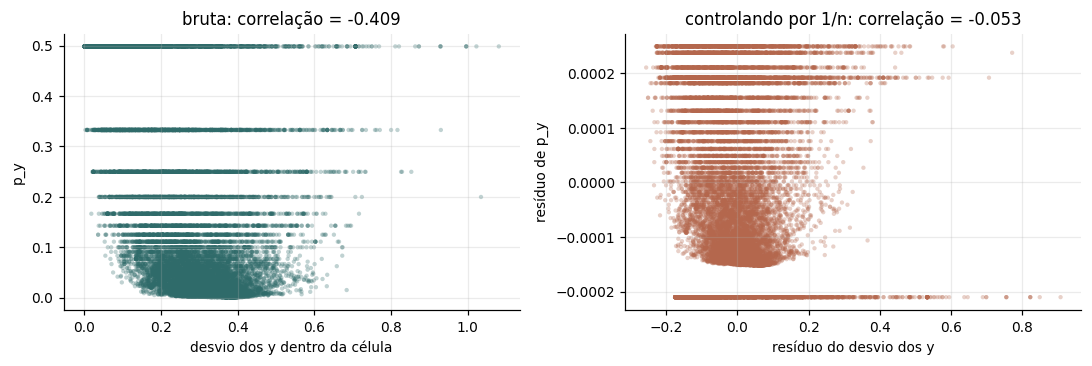

correlação bruta entre p_y e a dispersão dos y : -0.409
correlação parcial, controlando por 1/visitas  : -0.053


In [62]:
disp = [y_train[addr_tr[:, r_] == a].std() if np.sum(addr_tr[:, r_] == a) > 1 else np.nan
        for r_, a in zip(est.ram, est.address)]
est["dispersao_y"] = disp
sub = est.dropna(subset=["dispersao_y"])

corr = np.corrcoef(sub.p_y, sub.dispersao_y)[0, 1]
# parcial, controlando pelo número de visitas: p_y é função determinística de n
res_p = sub.p_y - np.poly1d(np.polyfit(1 / sub.visitas, sub.p_y, 1))(1 / sub.visitas)
res_d = sub.dispersao_y - np.poly1d(np.polyfit(1 / sub.visitas, sub.dispersao_y, 1))(1 / sub.visitas)
corr_parcial = np.corrcoef(res_p, res_d)[0, 1]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].scatter(sub.dispersao_y, sub.p_y, s=8, alpha=.3, color=COR_KAL, edgecolor="none")
ax[0].set(xlabel="desvio dos y dentro da célula", ylabel="p_y",
          title=f"bruta: correlação = {corr:.3f}")
ax[1].scatter(res_d, res_p, s=8, alpha=.3, color=COR_REW, edgecolor="none")
ax[1].set(xlabel="resíduo do desvio dos y", ylabel="resíduo de p_y",
          title=f"controlando por 1/n: correlação = {corr_parcial:.3f}")
plt.tight_layout(); plt.show()

print(f"correlação bruta entre p_y e a dispersão dos y : {corr:.3f}")
print(f"correlação parcial, controlando por 1/visitas  : {corr_parcial:.3f}")

---
## 5.3 Busca conjunta das seis covariâncias

Os estados iniciais ficam fixos em $x_{0,c} = x_{0,y} = 0$. As seis
covariâncias variam **ao mesmo tempo**, e não em grids separados com as demais
congeladas. As faixas estão na célula 0, ancoradas na escala de cada estado e de
cada observação.

| filtro | estado | observação $z$ | $q$ | $r$ | $p_0$ |
|---|---|---|---|---|---|
| peso $c$ | $[0,1)$ | $1{,}0$ | $10^{-4}$ a $10^{-2}$ | $0{,}05$ a $1$ | $0{,}1$ a $1$ |
| estimativa $y$ | $\approx 12$ | $y_i \in [10{,}5;\,13{,}5]$ | $1{,}5\cdot10^{-3}$ a $1{,}5\cdot10^{-1}$ | $1$ a $144$ | $12$ a $1440$ |

**Nenhuma covariância é zero.** Covariância nula não descreve uma gaussiana,
descreve um ponto exato no espaço de estados. Com $q = 0$ o filtro deixa de
admitir que o estado possa mudar e o ganho vai a zero; com $p_0 = 0$ ele congela
na crença inicial e nunca olha para o dado. Nos dois casos o que sobra não é
mais uma estimativa bayesiana, então o menor nível de cada eixo é positivo.

Por que a busca sequencial anterior não servia: ela varria um filtro com o outro
congelado, o que acha ótimo por coordenada e não ótimo conjunto. Além disso ela
tinha $q_y = 0$ e $r_c = 15$ entre os níveis, os dois fora do que a escala das
grandezas permite.

**O que conferir no resultado.** Um vencedor num extremo de eixo indica faixa
curta, não ótimo encontrado. A célula de diagnóstico logo abaixo reporta isso
eixo por eixo.

In [74]:
from itertools import product

combos = list(product(GRID_Q_C, GRID_R_C, GRID_P0_C, GRID_Q_Y, GRID_R_Y, GRID_P0_Y))

# com x0 = 0, dois modelos com as mesmas razões p0/r e q/r são idênticos
def razoes(qc, rc, p0c, qy, ry, p0y):
    return (round(p0c / rc, 12), round(qc / rc, 12),
            round(p0y / ry, 12), round(qy / ry, 12))

distintos = {razoes(*c) for c in combos}
print(f"grid conjunto: {len(combos)} configurações x {len(SEEDS_GRID)} seeds "
      f"= {len(combos)*len(SEEDS_GRID)} ajustes")
print(f"  modelos distintos: {len(distintos)} de {len(combos)} "
      f"({100*(1-len(distintos)/len(combos)):.0f}% de duplicatas exatas)\n")

cache, linhas, t0 = {}, [], time.perf_counter()
for n, (qc, rc, p0c, qy, ry, p0y) in enumerate(combos, 1):
    k = razoes(qc, rc, p0c, qy, ry, p0y)
    if k not in cache:
        e = []
        for s in SEEDS_GRID:
            pr = rkalwenn_rapido(IDX_GRID, y_train, SLOTS_TE, qc, rc, qy, ry,
                                 p0c, p0y, X0_C, X0_Y, seed=s)
            if np.isnan(pr).any():
                pr[np.isnan(pr)] = np.nanmean(pr)
            e.append(mean_absolute_error(y_test, pr))
        cache[k] = (float(np.mean(e)), float(np.std(e)))
    mae, dp = cache[k]
    linhas.append(dict(q_c=qc, r_c=rc, p0_c=p0c, q_y=qy, r_y=ry, p0_y=p0y,
                       MAE=mae, MAE_dp=dp))
    if n % 100 == 0:
        el = time.perf_counter() - t0
        print(f"  {n:>3}/{len(combos)}   {el/60:.1f} min, "
              f"faltam ~{el/n*(len(combos)-n)/60:.1f} min")

grid = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
MELHOR = {c: float(grid.loc[0, c]) for c in
          ["q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y"]}
MELHOR.update(x0_c=X0_C, x0_y=X0_Y)

print(f"\nconcluído em {(time.perf_counter()-t0)/60:.1f} min\n")
print("VENCEDOR")
for c, v in MELHOR.items():
    print(f"  {c:<5} = {v:g}")
print(f"  MAE = {grid.loc[0,'MAE']:.4f} ± {grid.loc[0,'MAE_dp']:.4f}")

grid conjunto: 729 configurações x 3 seeds = 2187 ajustes
  modelos distintos: 729 de 729 (0% de duplicatas exatas)

  100/729   1.9 min, faltam ~12.1 min
  200/729   3.9 min, faltam ~10.3 min
  300/729   5.6 min, faltam ~8.0 min
  400/729   7.1 min, faltam ~5.9 min
  500/729   8.7 min, faltam ~4.0 min
  600/729   10.1 min, faltam ~2.2 min
  700/729   11.6 min, faltam ~0.5 min

concluído em 12.0 min

VENCEDOR
  q_c   = 10
  r_c   = 0.05
  p0_c  = 1
  q_y   = 0.0015
  r_y   = 12
  p0_y  = 144
  x0_c  = 0
  x0_y  = 0
  MAE = 0.2471 ± 0.0012


In [64]:
cols = ["q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y", "MAE", "MAE_dp"]
print("AS 15 MELHORES CONFIGURAÇÕES\n")
print(grid.head(15)[cols].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

print(f"\nfaixa de MAE no grid inteiro: {grid.MAE.min():.4f} a {grid.MAE.max():.4f}")
print(f"configurações a menos de um desvio do vencedor: "
      f"{int((grid.MAE <= grid.loc[0,'MAE'] + grid.loc[0,'MAE_dp']).sum())} de {len(grid)}")

print("\nO vencedor caiu na borda de algum eixo?")
print("  (borda = faixa curta, não ótimo encontrado)")
for nome, niveis in [("q_c", GRID_Q_C), ("r_c", GRID_R_C), ("p0_c", GRID_P0_C),
                     ("q_y", GRID_Q_Y), ("r_y", GRID_R_Y), ("p0_y", GRID_P0_Y)]:
    v = MELHOR[nome]
    onde = ("MENOR nível" if v == min(niveis)
            else "MAIOR nível" if v == max(niveis) else "interior")
    print(f"  {nome:<5} = {v:<9g} {onde}")

AS 15 MELHORES CONFIGURAÇÕES

   q_c  r_c  p0_c    q_y  r_y  p0_y    MAE    MAE_dp
  0.01 0.05     1 0.0015  144  1440 0.2466  0.000184
 0.001 0.05     1 0.0015  144  1440 0.2467  0.000184
0.0001 0.05     1 0.0015  144  1440 0.2467  0.000184
  0.01 0.05   0.5 0.0015  144  1440 0.2467 0.0001839
 0.001 0.05   0.5 0.0015  144  1440 0.2467 0.0001838
0.0001 0.05   0.5 0.0015  144  1440 0.2468 0.0001838
  0.01 0.05     1  0.015  144  1440 0.2469  0.001059
 0.001 0.05     1  0.015  144  1440 0.2469  0.001058
0.0001 0.05     1  0.015  144  1440 0.2469  0.001058
  0.01 0.05   0.5  0.015  144  1440  0.247  0.001058
  0.01  0.3     1 0.0015  144  1440  0.247 0.0001835
 0.001 0.05   0.5  0.015  144  1440  0.247  0.001057
0.0001 0.05   0.5  0.015  144  1440  0.247  0.001057
  0.01 0.05   0.1 0.0015  144  1440  0.247 0.0001834
 0.001  0.3     1 0.0015  144  1440 0.2471 0.0001834

faixa de MAE no grid inteiro: 0.2466 a 0.8936
configurações a menos de um desvio do vencedor: 6 de 729

O vencedor caiu n

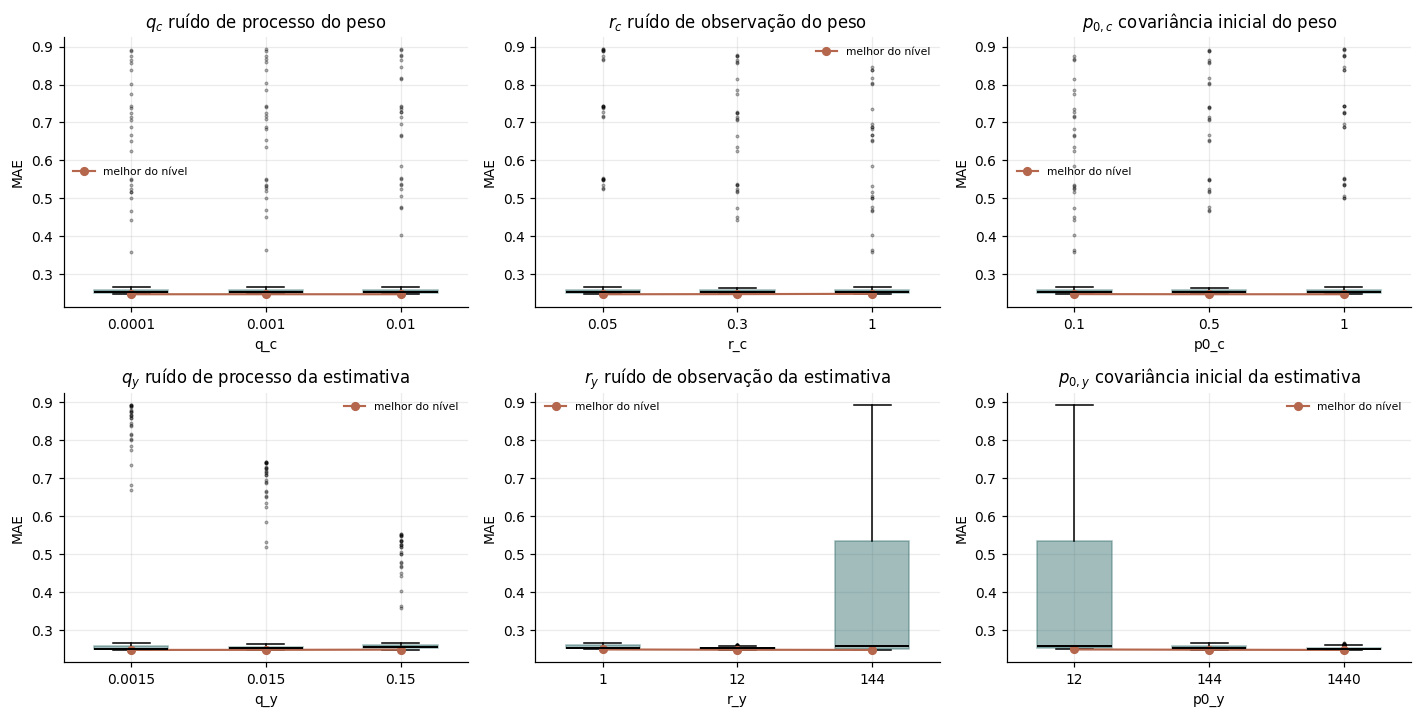

A caixa é a distribuição sobre TODAS as combinações das outras cinco
covariâncias. A linha liga o melhor de cada nível: eixo com linha plana
não influencia o ótimo.


In [65]:
eixos = [("q_c", GRID_Q_C, "$q_c$ ruído de processo do peso"),
         ("r_c", GRID_R_C, "$r_c$ ruído de observação do peso"),
         ("p0_c", GRID_P0_C, "$p_{0,c}$ covariância inicial do peso"),
         ("q_y", GRID_Q_Y, "$q_y$ ruído de processo da estimativa"),
         ("r_y", GRID_R_Y, "$r_y$ ruído de observação da estimativa"),
         ("p0_y", GRID_P0_Y, "$p_{0,y}$ covariância inicial da estimativa")]

fig, ax = plt.subplots(2, 3, figsize=(13, 6.6))
for a, (col, niveis, titulo) in zip(ax.ravel(), eixos):
    dados = [grid.loc[np.isclose(grid[col], v), "MAE"].values for v in niveis]
    bp = a.boxplot(dados, positions=range(len(niveis)), widths=.55, patch_artist=True,
                   medianprops=dict(color="black", lw=1.3),
                   flierprops=dict(marker=".", ms=3, alpha=.4))
    for caixa in bp["boxes"]:
        caixa.set(facecolor=COR_KAL, alpha=.45, edgecolor=COR_KAL)
    a.plot(range(len(niveis)), [d.min() for d in dados], "o-", color=COR_REW,
           ms=5, lw=1.4, label="melhor do nível")
    a.set(xticks=range(len(niveis)), xticklabels=[f"{v:g}" for v in niveis],
          xlabel=col, ylabel="MAE", title=titulo)
    a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

print("A caixa é a distribuição sobre TODAS as combinações das outras cinco")
print("covariâncias. A linha liga o melhor de cada nível: eixo com linha plana")
print("não influencia o ótimo.")

O QUE O VENCEDOR FAZ

  filtro do peso        kappa de regime 0.3583   janela ~  2.8 exemplos
  filtro da estimativa  kappa de regime 0.0032   janela ~310.3 exemplos

  confiança após 1, 6 e 50 visitas: 0.9528, 0.9969, 1.0000
  razão de peso entre célula de 50 visitas e de 1 visita: 1.05x
    na ReW crua essa razão é 50.00x, porque o peso é o contador puro
    razão 1.0x significaria ponderação uniforme entre RAM nodes

  estimativa após 1, 6 e 50 visitas: 10.929, 11.824, 11.998   (alvo médio 12.021)


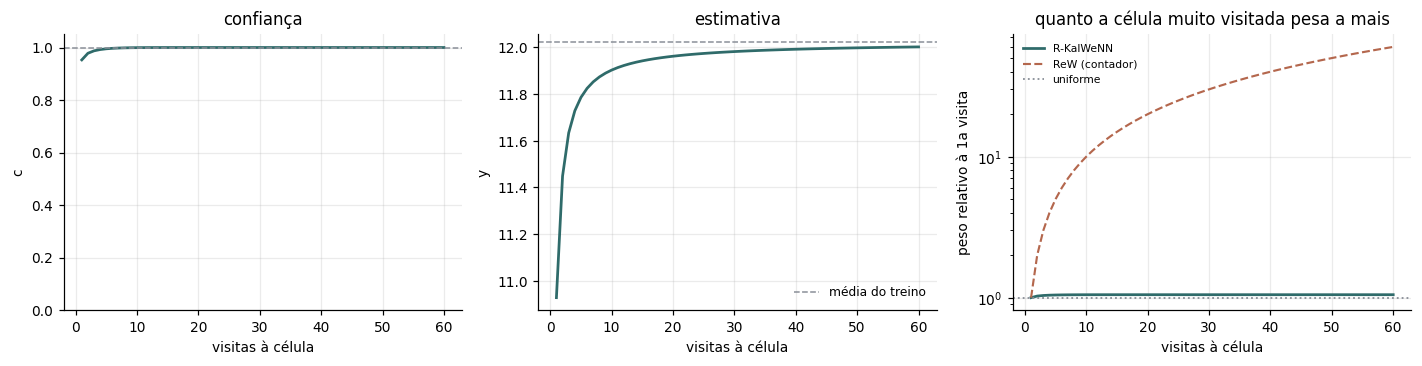

In [66]:
def kappa_regime(q, r, p0, n=3000):
    p = p0
    for _ in range(n):
        pb = p + q; k = pb / (pb + r); p = (1.0 - k) * pb
    return k

def trajetoria(q, r, p0, z, x0=0.0, N=60):
    x, p, out = x0, p0, []
    for _ in range(N):
        pb = p + q; k = pb / (pb + r); x += k * (z - x); p = (1.0 - k) * pb
        out.append(x)
    return np.array(out)

k_c = kappa_regime(MELHOR["q_c"], MELHOR["r_c"], MELHOR["p0_c"])
k_y = kappa_regime(MELHOR["q_y"], MELHOR["r_y"], MELHOR["p0_y"])
tc = trajetoria(MELHOR["q_c"], MELHOR["r_c"], MELHOR["p0_c"], 1.0, X0_C)
ty = trajetoria(MELHOR["q_y"], MELHOR["r_y"], MELHOR["p0_y"],
                float(y_train.mean()), X0_Y)

print("O QUE O VENCEDOR FAZ\n")
print(f"  filtro do peso        kappa de regime {k_c:.4f}   janela ~{1/k_c:>5.1f} exemplos")
print(f"  filtro da estimativa  kappa de regime {k_y:.4f}   janela ~{1/k_y:>5.1f} exemplos")
print(f"\n  confiança após 1, 6 e 50 visitas: {tc[0]:.4f}, {tc[5]:.4f}, {tc[49]:.4f}")
print(f"  razão de peso entre célula de 50 visitas e de 1 visita: {tc[49]/tc[0]:.2f}x")
print(f"    na ReW crua essa razão é 50.00x, porque o peso é o contador puro")
print(f"    razão 1.0x significaria ponderação uniforme entre RAM nodes")
print(f"\n  estimativa após 1, 6 e 50 visitas: {ty[0]:.3f}, {ty[5]:.3f}, {ty[49]:.3f}"
      f"   (alvo médio {y_train.mean():.3f})")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
n = np.arange(1, 61)
ax[0].plot(n, tc, lw=1.8, color=COR_KAL)
ax[0].axhline(1.0, color=COR_REF, ls="--", lw=1)
ax[0].set(xlabel="visitas à célula", ylabel="c", title="confiança", ylim=(0, 1.05))
ax[1].plot(n, ty, lw=1.8, color=COR_KAL)
ax[1].axhline(y_train.mean(), color=COR_REF, ls="--", lw=1, label="média do treino")
ax[1].set(xlabel="visitas à célula", ylabel="y", title="estimativa")
ax[1].legend(frameon=False, fontsize=8)
ax[2].plot(n, tc / tc[0], lw=1.8, color=COR_KAL, label="R-KalWeNN")
ax[2].plot(n, n, lw=1.4, color=COR_REW, ls="--", label="ReW (contador)")
ax[2].axhline(1.0, color=COR_REF, ls=":", lw=1.2, label="uniforme")
ax[2].set(xlabel="visitas à célula", ylabel="peso relativo à 1a visita",
          yscale="log", title="quanto a célula muito visitada pesa a mais")
ax[2].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

---
## 5.4 ReW contra R-KalWeNN

Mesmo binarizado, mesmo mapping, mesmo split, mesma configuração. As duas
implementações são as deste notebook, na mesma linguagem.

| dimensão | medida |
|---|---|
| MAE | precisão |
| desvio entre execuções | estabilidade |
| memória | bytes por célula × células ocupadas |

In [67]:
def mede(constroi, seeds=SEEDS_COMPARACAO):
    linhas = []
    for s in seeds:
        m = constroi(s)
        m.fit(Xb_train, y_train)
        p = m.predict(Xb_test)
        if np.isnan(p).any():
            p[np.isnan(p)] = np.nanmean(p)
        p[p == np.inf] = 0
        linhas.append((mean_absolute_error(y_test, p),
                       float(np.sqrt(mean_squared_error(y_test, p))),
                       m.memoria_bytes()))
    a = np.array(linhas, dtype=float)
    return {"MAE": a[:, 0].mean(), "MAE_dp": a[:, 0].std(),
            "RMSE": a[:, 1].mean(), "memoria_KB": a[:, 2].mean() / 1024}


MEDIAS_COMPARADAS = [MEDIA, "SimpleMean"]
resultados = []
for nome in MEDIAS_COMPARADAS:
    resultados.append(dict(modelo=f"ReW ({nome})",
                           **mede(lambda s, n=nome: RegressionWiSARD(
                               ADDR, medias_disponiveis()[n], MAPPING))))
resultados.append(dict(modelo="R-KalWeNN (grid)",
                       **mede(lambda s: RKalWeNN(ADDR, MAPPING, seed=s, **MELHOR))))

comp = pd.DataFrame(resultados)
print(comp.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))
print(f"\nreferência publicada (ReW, Median): MAE {TESE['ReW']:.3f}")
print("\nA ReW não depende da ordem de apresentação (soma e contagem comutam) e o")
print("mapping está fixo, então o desvio dela entre seeds é zero por construção.")

          modelo    MAE  MAE_dp   RMSE  memoria_KB
    ReW (Median) 0.2737  0.0000 0.3592    543.0938
ReW (SimpleMean) 0.2861  0.0000 0.3761    543.0938
R-KalWeNN (grid) 0.2467  0.0002 0.3309    905.1562

referência publicada (ReW, Median): MAE 0.278

A ReW não depende da ordem de apresentação (soma e contagem comutam) e o
mapping está fixo, então o desvio dela entre seeds é zero por construção.


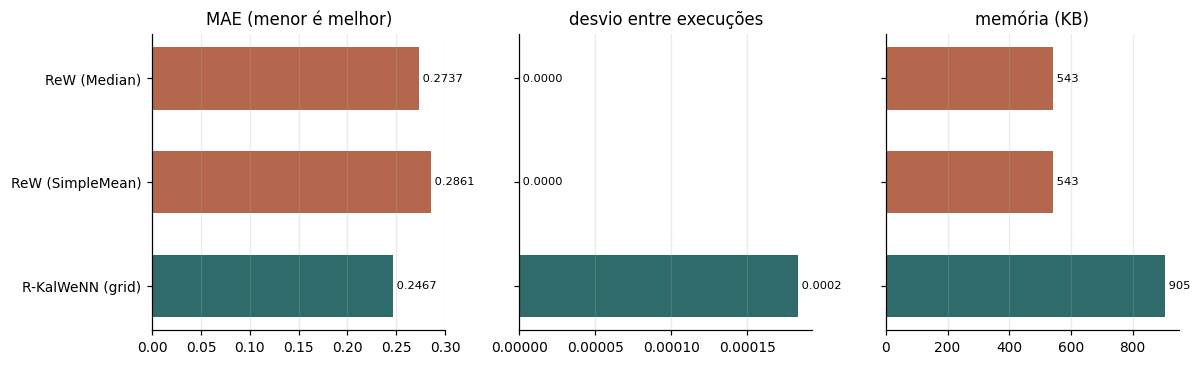

R-KalWeNN contra ReW (Median):
  MAE     : -9.9%
  RMSE    : -7.9%
  memória : 1.67x


In [68]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
ypos = np.arange(len(comp))[::-1]
cores = [COR_REW] * (len(comp) - 1) + [COR_KAL]

for a, col, tit, fmt in [
    (ax[0], "MAE",        "MAE (menor é melhor)",   lambda v: f"{v:.4f}"),
    (ax[1], "MAE_dp",     "desvio entre execuções", lambda v: f"{v:.4f}"),
    (ax[2], "memoria_KB", "memória (KB)",           lambda v: f"{v:,.0f}"),
]:
    a.barh(ypos, comp[col], color=cores, height=.6)
    a.set(yticks=ypos, yticklabels=comp.modelo if a is ax[0] else [], title=tit)
    a.grid(axis="y", visible=False)
    for p_, v in zip(ypos, comp[col]):
        a.text(v, p_, " " + fmt(v), va="center", fontsize=7.5)
plt.tight_layout(); plt.show()

r_kal = comp[comp.modelo.str.startswith("R-KalWeNN")].iloc[0]
r_rew = comp[comp.modelo == f"ReW ({MEDIA})"].iloc[0]
print(f"R-KalWeNN contra ReW ({MEDIA}):")
print(f"  MAE     : {(r_kal.MAE/r_rew.MAE - 1)*100:+.1f}%")
print(f"  RMSE    : {(r_kal.RMSE/r_rew.RMSE - 1)*100:+.1f}%")
print(f"  memória : {r_kal.memoria_KB/r_rew.memoria_KB:.2f}x")

---
# Parte 6 — Trocando a média da inferência

O treino não muda: cada endereço visitado guarda uma confiança $c_k$ e um valor
esperado $y_k$. O que muda é só como as RAM nodes são agregadas na inferência.

A ReW crua entra como controle, com a mesma binarização, o mesmo `mapping` e o
mesmo split, para separar duas coisas que andam juntas: quanto vem da agregação
escolhida e quanto vem do filtro.

**Regime.** `p0_c = 1`, confiança informativa. Com `p0_c = 1000`, que venceu o
grid da Parte 5, a confiança satura em 0,985 já na primeira visita e a razão de
peso entre uma célula de 50 visitas e uma de 1 visita cai para 1,015x, o que
tornaria ponderada e não ponderada indistinguíveis. Os valores estão em
`KAL_MEDIAS`, na célula 0.

**Métricas.** MAE, RMSE e $R^2$, as três em escala `log1p`.

**Previsão registrada antes de rodar.** Na configuração fixada a ReW crua já
chega a MAE 0,248 com a família harmônica, contra 0,2492 do R-KalWeNN com a
aritmética ponderada. Se o R-KalWeNN com as médias ponderadas não passar disso,
a leitura é que o ganho do filtro vinha de deixar de premiar célula muito
visitada, e não do filtro em si.

In [69]:
def r2(y_true, y_pred):
    ss_res = float(np.sum((y_true - y_pred) ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    return 1.0 - ss_res / ss_tot


def limpa(p):
    """Substitui não finito, como nas linhas 316-317 do houseprice.py."""
    p = np.asarray(p, dtype=float).copy()
    nao_finito = ~np.isfinite(p)
    n = int(nao_finito.sum())
    if n:
        p[np.isnan(p)] = np.nanmean(p[np.isfinite(p)]) if np.isfinite(p).any() else 0.0
        p[~np.isfinite(p)] = 0.0
    return p, n


def avalia(pred):
    p, n = limpa(pred)
    return {"MAE": mean_absolute_error(y_test, p),
            "RMSE": float(np.sqrt(mean_squared_error(y_test, p))),
            "R2": r2(y_test, p), "nao_finito": n}


print("regime de confiança informativa:")
for k, v in KAL_MEDIAS.items():
    print(f"  {k:<5} = {v:g}")

_c, _p = 0.0, KAL_MEDIAS["p0_c"]
_tab = {}
for _n in range(1, 51):
    _pp = _p + KAL_MEDIAS["q_c"]; _k = _pp / (_pp + KAL_MEDIAS["r_c"])
    _c += _k * (1.0 - _c); _p = (1.0 - _k) * _pp
    _tab[_n] = _c
print(f"\nconfiança após 1, 6 e 50 visitas: "
      f"{_tab[1]:.4f}, {_tab[6]:.4f}, {_tab[50]:.4f}")
print(f"razão de peso entre célula de 50 visitas e de 1 visita: {_tab[50]/_tab[1]:.2f}x")
print(f"  (na ReW crua essa razão seria 50.00x, o contador puro)")

regime de confiança informativa:
  q_c   = 0.1
  r_c   = 15
  q_y   = 0.001
  r_y   = 1
  x0_c  = 0
  x0_y  = 0
  p0_c  = 1
  p0_y  = 1000

confiança após 1, 6 e 50 visitas: 0.0683, 0.3585, 0.9818
razão de peso entre célula de 50 visitas e de 1 visita: 14.37x
  (na ReW crua essa razão seria 50.00x, o contador puro)


In [70]:
linhas, t0 = [], time.perf_counter()

for nome, m in medias_ponderadas().items():
    reps = []
    for s in SEEDS_MEDIAS:
        mod = RKalWeNN(ADDR, MAPPING, seed=s, media=m, **KAL_MEDIAS).fit(Xb_train, y_train)
        reps.append(avalia(mod.predict(Xb_test)))
    linhas.append({"modelo": "R-KalWeNN", "media": nome,
                   "MAE": float(np.mean([r["MAE"] for r in reps])),
                   "MAE_dp": float(np.std([r["MAE"] for r in reps])),
                   "RMSE": float(np.mean([r["RMSE"] for r in reps])),
                   "R2": float(np.mean([r["R2"] for r in reps])),
                   "nao_finito": int(np.max([r["nao_finito"] for r in reps]))})
    print(f"  R-KalWeNN  {nome:<18} ok  ({(time.perf_counter()-t0)/60:.1f} min)")

for nome, m in medias_disponiveis().items():
    if nome not in medias_ponderadas():
        continue                                   # só as sete que têm par
    mod = RegressionWiSARD(ADDR, m, MAPPING).fit(Xb_train, y_train)
    r = avalia(mod.predict(Xb_test))
    linhas.append({"modelo": "ReW", "media": nome, "MAE": r["MAE"], "MAE_dp": 0.0,
                   "RMSE": r["RMSE"], "R2": r["R2"], "nao_finito": r["nao_finito"]})
    print(f"  ReW        {nome:<18} ok  ({(time.perf_counter()-t0)/60:.1f} min)")

med = pd.DataFrame(linhas)
print(f"\nconcluído em {(time.perf_counter()-t0)/60:.1f} min")

  R-KalWeNN  PowerMean(2)       ok  (0.3 min)
  R-KalWeNN  HarmonicMean       ok  (0.5 min)
  R-KalWeNN  HarmonicPower(2)   ok  (0.8 min)
  R-KalWeNN  GeometricMean      ok  (1.2 min)
  R-KalWeNN  ExponentialMean    ok  (1.5 min)
  R-KalWeNN  SimpleMean         ok  (1.8 min)
  R-KalWeNN  Median             ok  (2.1 min)
  ReW        PowerMean(2)       ok  (2.2 min)
  ReW        HarmonicMean       ok  (2.2 min)
  ReW        HarmonicPower(2)   ok  (2.3 min)


/var/folders/kn/t8jqs6cn3gs41cylbls499h80000gn/T/ipykernel_1442/3943008123.py:62: RuntimeWarning: overflow encountered in scalar multiply
  g *= mu; m += 1


  ReW        GeometricMean      ok  (2.3 min)
  ReW        ExponentialMean    ok  (2.4 min)
  ReW        SimpleMean         ok  (2.5 min)
  ReW        Median             ok  (2.6 min)

concluído em 2.6 min


In [71]:
tab = med.pivot(index="media", columns="modelo", values="MAE")
tab["diferenca"] = tab["R-KalWeNN"] - tab["ReW"]
tab["ganho_%"] = (tab["R-KalWeNN"] / tab["ReW"] - 1) * 100
print("MAE por média (escala log1p)\n")
print(tab.sort_values("R-KalWeNN").to_string(float_format=lambda v: f"{v:,.4f}"))

print("\n\nR-KalWeNN, as três métricas\n")
rk = med[med.modelo == "R-KalWeNN"].sort_values("MAE")
print(rk[["media", "MAE", "MAE_dp", "RMSE", "R2", "nao_finito"]].to_string(
    index=False, float_format=lambda v: f"{v:,.4f}"))

quebradas = med[med.nao_finito > 0]
if len(quebradas):
    print("\nmédias com valor não finito, substituído antes das métricas:")
    print(quebradas[["modelo", "media", "nao_finito"]].to_string(index=False))

MAE por média (escala log1p)

modelo            R-KalWeNN     ReW  diferenca  ganho_%
media                                                  
HarmonicPower(2)     0.2533  0.2479     0.0054   2.1798
HarmonicMean         0.2534  0.2480     0.0054   2.1927
GeometricMean        0.2534 12.0373   -11.7838 -97.8945
SimpleMean           0.2535  0.2861    -0.0326 -11.4036
PowerMean(2)         0.2536  0.2480     0.0055   2.2343
ExponentialMean      0.2539  0.2479     0.0060   2.4092
Median               0.2760  0.2737     0.0023   0.8461


R-KalWeNN, as três métricas

           media    MAE  MAE_dp   RMSE     R2  nao_finito
HarmonicPower(2) 0.2533  0.0028 0.3382 0.3070           0
    HarmonicMean 0.2534  0.0027 0.3381 0.3071           0
   GeometricMean 0.2534  0.0026 0.3381 0.3073           0
      SimpleMean 0.2535  0.0025 0.3381 0.3075           0
    PowerMean(2) 0.2536  0.0024 0.3380 0.3077           0
 ExponentialMean 0.2539  0.0012 0.3371 0.3114           0
          Median 0.2760  0.00

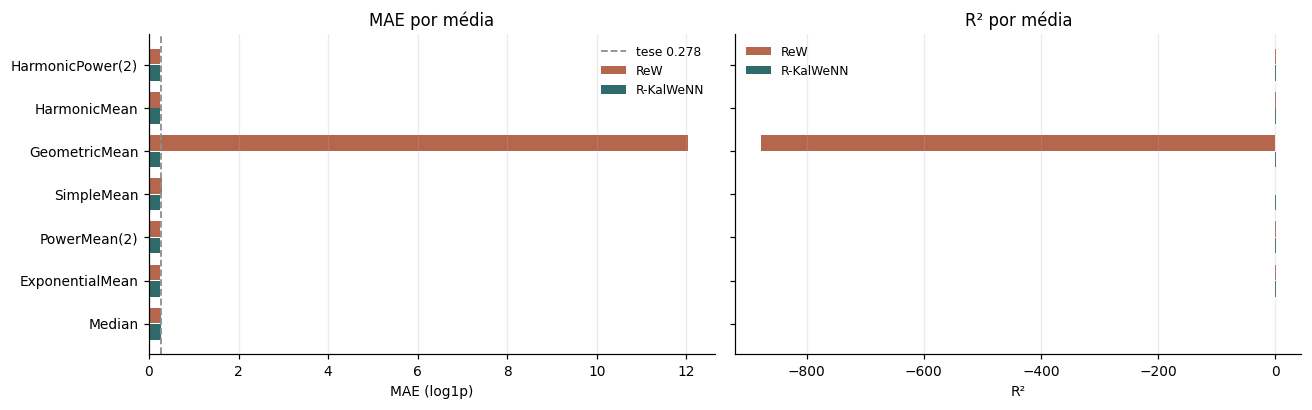

In [72]:
ordem = tab.sort_values("R-KalWeNN", ascending=False).index
x = np.arange(len(ordem))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(x + .19, tab.loc[ordem, "ReW"], height=.36, color=COR_REW, label="ReW")
ax[0].barh(x - .19, tab.loc[ordem, "R-KalWeNN"], height=.36, color=COR_KAL, label="R-KalWeNN")
ax[0].axvline(TESE["ReW"], color=COR_REF, ls="--", lw=1.2, label=f"tese {TESE['ReW']}")
ax[0].set(yticks=x, yticklabels=ordem, xlabel="MAE (log1p)", title="MAE por média")
ax[0].grid(axis="y", visible=False); ax[0].legend(frameon=False, fontsize=8)

rk = med[med.modelo == "R-KalWeNN"].set_index("media").loc[ordem]
rw = med[med.modelo == "ReW"].set_index("media").loc[ordem]
ax[1].barh(x + .19, rw["R2"], height=.36, color=COR_REW, label="ReW")
ax[1].barh(x - .19, rk["R2"], height=.36, color=COR_KAL, label="R-KalWeNN")
ax[1].set(yticks=x, yticklabels=[], xlabel="R²", title="R² por média")
ax[1].grid(axis="y", visible=False); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()